# Análise do Espaço Químico — Viés, Cobertura e Convergência do AG

Inspirado em **Monterrubio-Chanca & von Rudorff (2025), JCTC 21, 12810–12819**  
*"Representative Random Sampling of Chemical Space"*

O artigo propõe medir o **viés de bases de dados** em relação ao espaço químico subestante usando a estatística Kolmogorov–Smirnov (KS) sobre a distribuição de stoichiometries. Aqui adaptamos essa metodologia para:

1. **Perfil da base de sementes** (`banco_smiles_aromatizados.parquet`) — distribuição de fórmulas moleculares, MW, elementos e tipos de anéis.
2. **KS generacional** — como a distribuição estequiométrica das moléculas aceitas evolui ao longo das 117 gerações do AG.
3. **Cobertura do espaço** — o AG explora ou converge para uma subregiâo da base de sementes?
4. **Discussão** — limitações e o que a análise RRS completa (com `nablachem.space`) acrescentaria.

> **Nota sobre `nablachem`:** o pacote `nablachem.space` (que gera amostras uniformes do espaço químico por partições inteiras + MCMC) não está instalado neste ambiente. A análise KS aqui usa a própria base de sementes como referência, medindo o quanto o AG deriva estequiometricamente em relação ao ponto de partida.

In [1]:
from __future__ import annotations

import glob
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec
from scipy.stats import ks_2samp
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, QED
from rdkit.Chem.rdMolDescriptors import CalcTPSA
from collections import Counter
from tqdm.auto import tqdm

plt.rcParams.update({
    'figure.dpi': 130,
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

DIR_EXEC = 'data/execucoes/20261008_131438/geracoes'
PARQUET_SEMENTES = 'data/banco_smiles_aromatizados.parquet'
print('Configuração OK')

Configuração OK


## 1  Funções de caracterização molecular

In [2]:
ELEM_INTEREST = ['C', 'H', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']

def mol_features(smiles: str) -> dict | None:
    """Extrai features estequiométricas e topológicas de um SMILES."""
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None
        formula = rdMolDescriptors.CalcMolFormula(mol)
        hac = mol.GetNumHeavyAtoms()
        mw  = Descriptors.ExactMolWt(mol)
        ring_info = mol.GetRingInfo()
        arom_rings = sum(
            1 for ring in ring_info.AtomRings()
            if all(mol.GetAtomWithIdx(i).GetIsAromatic() for i in ring)
        )
        # contagem de elementos
        elem_count = Counter(a.GetSymbol() for a in mol.GetAtoms())
        # fração C (heurística de conjugação via backbobe carbonáceo)
        frac_c = elem_count.get('C', 0) / hac if hac > 0 else 0
        # heteroátomos pesados
        heavy_hetero = sum(v for k, v in elem_count.items()
                           if k not in ('C', 'H'))
        d = {
            'formula': formula,
            'mw': mw,
            'hac': hac,
            'n_rings': ring_info.NumRings(),
            'arom_rings': arom_rings,
            'frac_c': frac_c,
            'heavy_hetero': heavy_hetero,
        }
        for el in ELEM_INTEREST:
            d[f'n_{el}'] = elem_count.get(el, 0)
        return d
    except Exception:
        return None


def feat_df(smiles_col: pd.Series, label: str = '') -> pd.DataFrame:
    """Aplica mol_features a uma coluna SMILES e retorna DataFrame."""
    rows = [mol_features(s) for s in tqdm(smiles_col, desc=label, leave=False)]
    return pd.DataFrame([r for r in rows if r is not None])


def ks_vs_ref(df_ref: pd.DataFrame, df_gen: pd.DataFrame,
              cols: list[str] = None) -> dict[str, float]:
    """Calcula KS stat entre df_gen e df_ref para cada coluna.
    Retorna dict col -> ks_stat."""
    if cols is None:
        cols = ['mw', 'hac', 'n_rings', 'arom_rings', 'frac_c',
                'heavy_hetero', 'n_N', 'n_O', 'n_S']
    result = {}
    for col in cols:
        if col in df_ref.columns and col in df_gen.columns:
            stat, _ = ks_2samp(df_ref[col].dropna().values,
                                df_gen[col].dropna().values)
            result[col] = round(stat, 4)
    return result

print('Funções definidas')

Funções definidas


## 2  Perfil da base de sementes

In [3]:
df_seed_raw = pd.read_parquet(PARQUET_SEMENTES)
print(f'Base de sementes: {len(df_seed_raw):,} moléculas')
print(f'Colunas SMILES disponíveis: smiles, SMILES_Aromatico, SMILES_Canonico_Complexo')

# Usa a coluna 'smiles' (canônico final após aromatização)
df_seed = feat_df(df_seed_raw['smiles'], 'Sementes')
print(f'\nMoléculas válidas: {len(df_seed):,}/{len(df_seed_raw):,}')

Base de sementes: 5,974 moléculas
Colunas SMILES disponíveis: smiles, SMILES_Aromatico, SMILES_Canonico_Complexo


Sementes:   0%|          | 0/5974 [00:00<?, ?it/s]

[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 29 30 34
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 18 19 22
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 18 19 20 22 23
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 4 5 9 10 13
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 8 9 30
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 10 11 14 16 21
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 23 24 29 32
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 24 25 27 29
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 11 14 15
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 6 9 10 13
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 11 12 13 20 21
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 26
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 7 8 9
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 12 13 16 17 18
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 9 14 15
[07:56:08] Can't kekulize mol.  Unkekulized atoms:

[07:56:08] Can't kekulize mol.  Unkekulized atoms: 6 7 19 20 26
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 5 24 25
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 6 9 10 33
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 7 11 28
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 12 13 14 20 23
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 4 5 28 29 30
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 23 24 25 34
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 7 19 30
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 14 15 16 18 19
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 4 5 6 8 13
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 11 14 18
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 8
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 13 14 35
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 4 5 6 31
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 19 20 26 27 38
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 6 1

[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 7 22 25
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 7 22 25
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 13 14 15 16 29
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 9 10 11 13 19
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 28 29 31
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 5 24
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 2 3 4 15 16
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 10 12 34
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 5 7 13
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 2 3 4 6 27
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 2 4 6 8 9
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 4 5 20 26 27
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 16 17 19 20 22
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 2 3 4 25 29
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 9 10 11 15 19
[07:56:08] Can't kekulize mol.  Unkekulized atoms

[07:56:08] Can't kekulize mol.  Unkekulized atoms: 2 3 5 7 10
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 1 2 3 25 32
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 7 11 17
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 1 2 3 29 30
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 5 24 28
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 10
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 25 26 30 42
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 8
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 5 6 7 28 29
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 4 6 7 18
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 2 31 33
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 15 16 17 22 27
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 12 13 14 19 20
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 10 11 12 13 39
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 14 15 16 27 31
[07:56:08] Can't kekulize mol.  Unkekulized atoms: 3 5 6

... (26 outputs left out)

[07:56:10] Can't kekulize mol.  Unkekulized atoms: 6 12 13 19 20
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 4 5 6 12
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 5 6 11 31
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 8 9 12 14 15
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 3 4 9 10 13
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 3 4 5 9 10
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 6 17 18 22 23
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 2 3 4 26 27
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 3 4 5 34
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 5 7 10 11
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 4 5 9 11 15
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 1 2 21 24 25
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 17 18 19 22
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 26 27 37
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 2 4 26 28 29
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 2 3 4 22 27

[07:56:10] Can't kekulize mol.  Unkekulized atoms: 7 8 9 10 14
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 14 15 16 23 24
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 14 15 18 23
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 6 10 11 12 27
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 4 5 33 34 35
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 3 4 5 8
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 3 4 5 10 11
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 3 4 5 10 11
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 5 6 7 8 35
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 5 6 30
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 15 16 17 26 27
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 13 14 15 20 25
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 4 8 14
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 5 9 10
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 3 4 20 21 23
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 5 6 30 31 3

[07:56:10] Can't kekulize mol.  Unkekulized atoms: 5 6 31 32 35
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 5 6 7 10 11
[07:56:10] Can't kekulize mol.  Unkekulized atoms: 11 13 18 22
                                                               


Moléculas válidas: 2,573/5,974


In [4]:
print('=== Perfil estatístico da base de sementes ===')
cols_show = ['mw', 'hac', 'n_rings', 'arom_rings', 'n_N', 'n_O', 'n_S', 'frac_c']
df_seed[cols_show].describe().round(2)

=== Perfil estatístico da base de sementes ===


,mw,hac,n_rings,arom_rings,n_N,n_O,n_S,frac_c
count,2573.00,2573.00,2573.0,2573.00,2573.00,2573.00,2573.00,2573.00
mean,522.92,32.43,2.0,0.18,3.77,6.60,1.99,0.56
std,80.26,5.33,0.0,0.40,1.71,2.93,1.25,0.09
min,315.24,17.00,2.0,0.00,0.00,0.00,0.00,0.23
25%,466.00,29.00,2.0,0.00,3.00,5.00,1.00,0.50
50%,518.10,32.00,2.0,0.00,4.00,6.00,2.00,0.56
75%,573.08,36.00,2.0,0.00,5.00,8.00,3.00,0.62
max,866.20,57.00,2.0,2.00,10.00,18.00,8.00,0.85


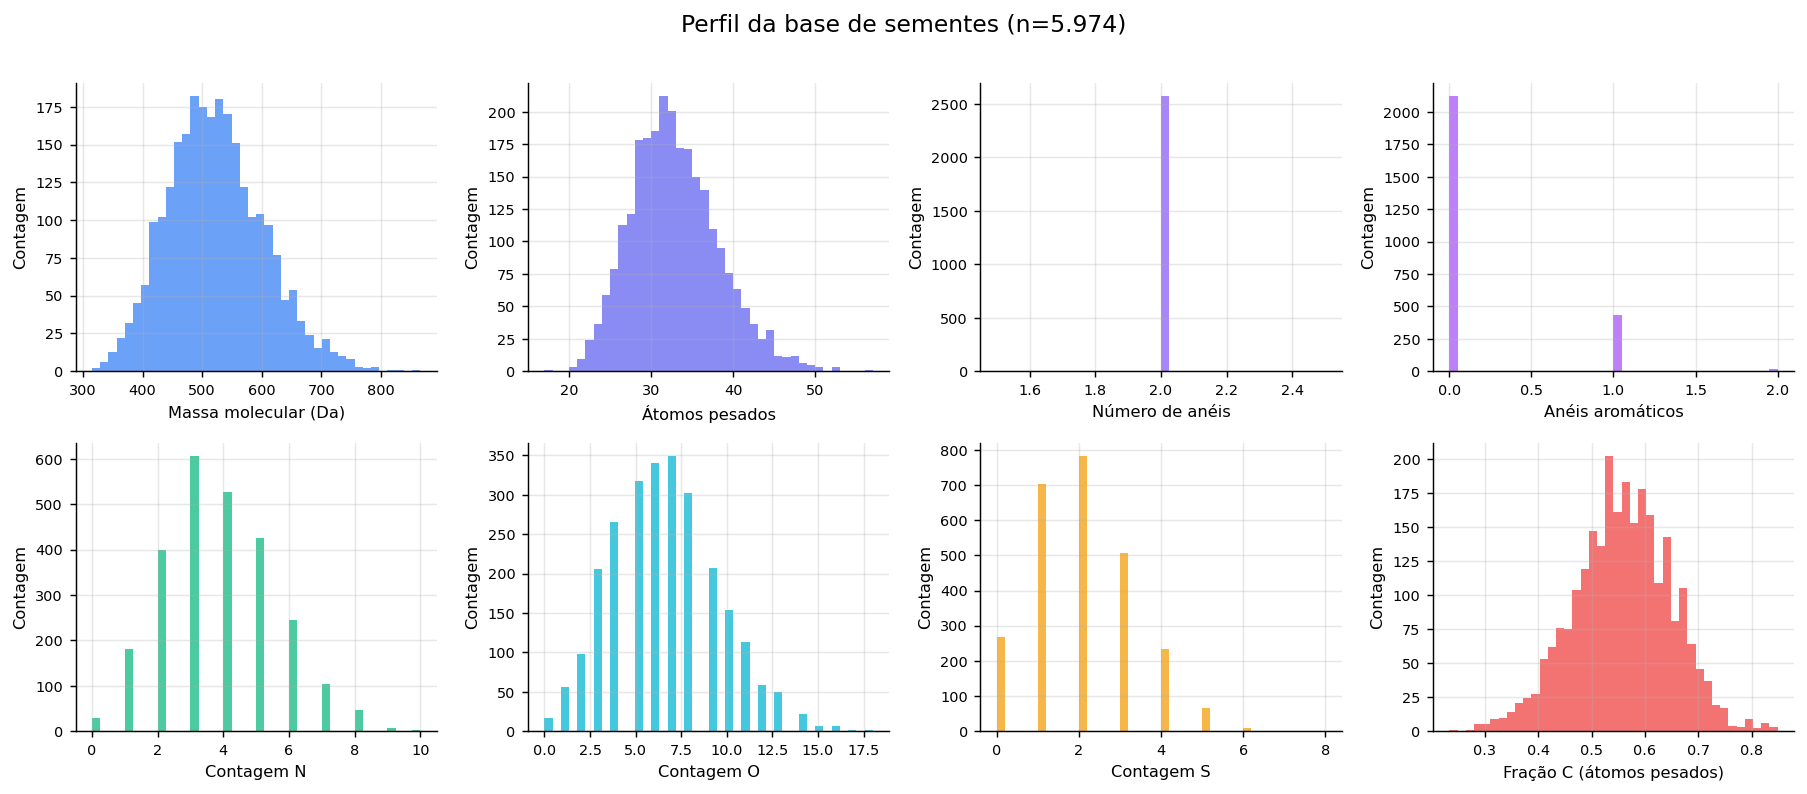

Figura salva: data/fig_perfil_sementes.png


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
fig.suptitle('Perfil da base de sementes (n=5.974)', fontsize=13, y=1.01)

pairs = [
    ('mw',          'Massa molecular (Da)',      '#3b82f6'),
    ('hac',         'Átomos pesados',            '#6366f1'),
    ('n_rings',     'Número de anéis',           '#8b5cf6'),
    ('arom_rings',  'Anéis aromáticos',          '#a855f7'),
    ('n_N',         'Contagem N',                '#10b981'),
    ('n_O',         'Contagem O',                '#06b6d4'),
    ('n_S',         'Contagem S',                '#f59e0b'),
    ('frac_c',      'Fração C (átomos pesados)', '#ef4444'),
]

for ax, (col, label, color) in zip(axes.flat, pairs):
    data = df_seed[col].dropna()
    ax.hist(data, bins=40, color=color, alpha=0.75, edgecolor='none')
    ax.set_xlabel(label, fontsize=9)
    ax.set_ylabel('Contagem', fontsize=9)
    ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig('data/fig_perfil_sementes.png', bbox_inches='tight', dpi=150)
plt.show()
print('Figura salva: data/fig_perfil_sementes.png')

In [6]:
# Diversidade de fórmulas moleculares
n_total = len(df_seed)
n_formulas = df_seed['formula'].nunique()
print(f'Fórmulas moleculares únicas: {n_formulas:,} / {n_total:,} moléculas')
print(f'Razão diversidade: {n_formulas/n_total:.2%}')
print()

# Distribuição de elementos
print('=== Presença de elementos (% moléculas) ===')
for el in ELEM_INTEREST:
    col = f'n_{el}'
    if col in df_seed.columns:
        pct = (df_seed[col] > 0).mean() * 100
        mean_n = df_seed.loc[df_seed[col] > 0, col].mean()
        print(f'  {el:3s}  presente em {pct:5.1f}%   | média quando presente: {mean_n:.1f}')

print()
print('=== Anéis aromáticos ===')
arom_dist = df_seed['arom_rings'].value_counts().sort_index()
for n, cnt in arom_dist.items():
    print(f'  {int(n)} anel(is) aromático(s): {cnt:5,} mol ({cnt/n_total:.1%})')

Fórmulas moleculares únicas: 2,567 / 2,573 moléculas
Razão diversidade: 99.77%

=== Presença de elementos (% moléculas) ===
  C    presente em 100.0%   | média quando presente: 18.1
  H    presente em   0.0%   | média quando presente: nan
  N    presente em  98.9%   | média quando presente: 3.8
  O    presente em  99.3%   | média quando presente: 6.6
  S    presente em  89.6%   | média quando presente: 2.2
  F    presente em  21.4%   | média quando presente: 3.3
  Cl   presente em  21.4%   | média quando presente: 1.1
  Br   presente em  22.4%   | média quando presente: 1.1
  I    presente em   0.0%   | média quando presente: nan
  P    presente em   0.0%   | média quando presente: nan

=== Anéis aromáticos ===
  0 anel(is) aromático(s): 2,121 mol (82.4%)
  1 anel(is) aromático(s):   434 mol (16.9%)
  2 anel(is) aromático(s):    18 mol (0.7%)


## 3  KS generacional — deriva estequiométrica ao longo do AG

Para cada geração carregamos as moléculas aceitas, calculamos suas features e computamos o KS em relação à base de sementes. Um KS alto indica que o AG gerou moléculas com distribuição estequiométrica diferente da base inicial — podendo indicar exploração (desejável) ou deriva não controlada (indesejável).

Analogamente à Figura 4 de Monterrubio-Chanca (2025), aqui a "base" é o banco de sementes e o "espaço de referência" é a amostra gerada.

In [7]:
KS_COLS = ['mw', 'hac', 'n_rings', 'arom_rings', 'frac_c',
           'heavy_hetero', 'n_N', 'n_O', 'n_S']

arquivos = sorted(glob.glob(f'{DIR_EXEC}/g*_aceitas.parquet'))
print(f'{len(arquivos)} gerações encontradas')

registros = []
for arq in tqdm(arquivos, desc='Gerações'):
    gen_num = int(os.path.basename(arq).split('_')[0].replace('g', ''))
    df_g = pd.read_parquet(arq)
    if df_g.empty or 'smiles' not in df_g.columns:
        continue
    # Amostra até 2000 para eficiência (KS converge rápido)
    sample = df_g['smiles'].sample(min(2000, len(df_g)), random_state=42)
    df_feat = feat_df(sample, label='')
    if df_feat.empty:
        continue
    ks = ks_vs_ref(df_seed, df_feat, cols=KS_COLS)
    # KS médio (agregado — análogo ao KS reportado no paper)
    ks_mean = np.mean(list(ks.values()))
    registros.append({'geracao': gen_num, 'n_aceitas': len(df_g),
                      'ks_medio': ks_mean, **ks,
                      # features médias da geração
                      'mw_med': df_feat['mw'].median(),
                      'arom_rings_med': df_feat['arom_rings'].median(),
                      'frac_c_med': df_feat['frac_c'].median()})

df_ks = pd.DataFrame(registros).sort_values('geracao').reset_index(drop=True)
print(f'\nKS calculado para {len(df_ks)} gerações')
df_ks[['geracao','n_aceitas','ks_medio','mw','arom_rings','frac_c']].head(10)

117 gerações encontradas


Gerações:   0%|          | 0/117 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

 12%|█▎        | 250/2000 [00:00<00:00, 2380.64it/s]

 24%|██▍       | 489/2000 [00:00<00:00, 2272.69it/s]

 36%|███▌      | 717/2000 [00:00<00:00, 2104.36it/s]

... (355 outputs left out)

Gerações:  99%|█████████▉| 116/117 [00:26<00:00, 39.46it/s]

Gerações: 100%|██████████| 117/117 [00:26<00:00,  4.40it/s]


KS calculado para 116 gerações


,geracao,n_aceitas,ks_medio,mw,arom_rings,frac_c
0,1,4333,0.034911,0.0573,0.0527,0.0486
1,2,3925,0.050611,0.0320,0.0072,0.0935
2,3,3590,0.055156,0.0271,0.0038,0.1072
3,4,3325,0.062111,0.0425,0.0067,0.1198
4,5,3092,0.061700,0.0516,0.0037,0.1035
5,6,2857,0.062378,0.0456,0.0032,0.1056
6,7,2652,0.062622,0.0324,0.0148,0.1109
7,8,2497,0.067444,0.0592,0.0023,0.1170
8,9,2320,0.068044,0.0586,0.0038,0.1096
9,10,2156,0.064200,0.0300,0.0005,0.0978


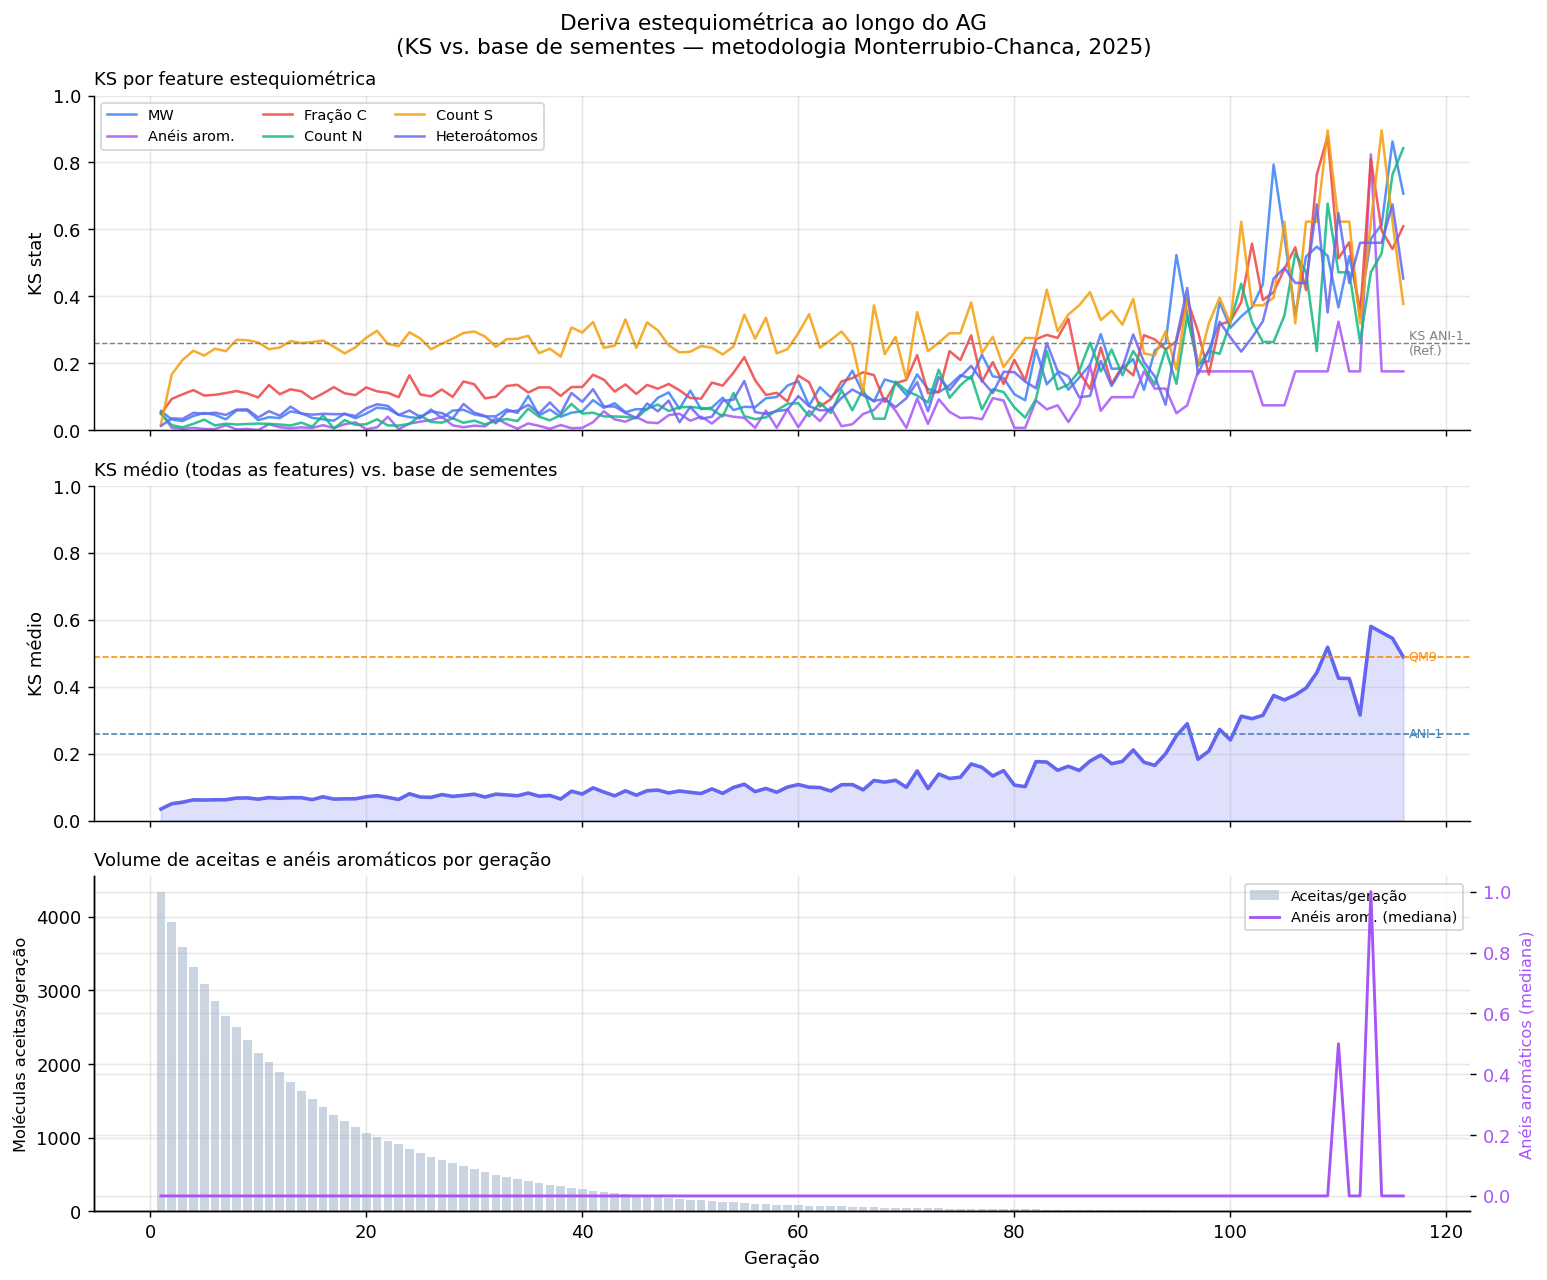

Figura salva: data/fig_ks_generacional.png


In [8]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
fig.suptitle('Deriva estequiométrica ao longo do AG\n'
             '(KS vs. base de sementes — metodologia Monterrubio-Chanca, 2025)', fontsize=12)

gen = df_ks['geracao']

# Painel 1: KS por feature
ax = axes[0]
for col, label, color in [
    ('mw',          'MW',              '#3b82f6'),
    ('arom_rings',  'Anéis arom.',     '#a855f7'),
    ('frac_c',      'Fração C',        '#ef4444'),
    ('n_N',         'Count N',         '#10b981'),
    ('n_S',         'Count S',         '#f59e0b'),
    ('heavy_hetero','Heteroátomos',    '#6366f1'),
]:
    if col in df_ks:
        ax.plot(gen, df_ks[col], label=label, color=color, lw=1.4, alpha=0.85)
ax.set_ylabel('KS stat', fontsize=10)
ax.legend(ncol=3, fontsize=8)
ax.set_ylim(0, 1)
ax.axhline(0.26, color='gray', lw=0.8, ls='--', label='KS ANI-1 ≈ 0.26')
ax.text(gen.iloc[-1]+0.5, 0.26, 'KS ANI-1\n(Ref.)', fontsize=7, va='center', color='gray')
ax.set_title('KS por feature estequiométrica', fontsize=10, loc='left')

# Painel 2: KS médio
ax = axes[1]
ax.fill_between(gen, df_ks['ks_medio'], alpha=0.2, color='#6366f1')
ax.plot(gen, df_ks['ks_medio'], color='#6366f1', lw=2)
ax.set_ylabel('KS médio', fontsize=10)
ax.set_title('KS médio (todas as features) vs. base de sementes', fontsize=10, loc='left')
# Referências do paper
ax.axhline(0.26, color='steelblue', lw=0.9, ls='--')
ax.axhline(0.49, color='darkorange', lw=0.9, ls='--')
ax.text(gen.iloc[-1]+0.5, 0.26, 'ANI-1', fontsize=7, va='center', color='steelblue')
ax.text(gen.iloc[-1]+0.5, 0.49, 'QM9',   fontsize=7, va='center', color='darkorange')
ax.set_ylim(0, 1)

# Painel 3: acumulado de aceitas + anéis aromáticos medianos
ax = axes[2]
ax2 = ax.twinx()
ax.bar(gen, df_ks['n_aceitas'], color='#cbd5e1', width=0.8, label='Aceitas/geração')
ax2.plot(gen, df_ks['arom_rings_med'], color='#a855f7', lw=1.6, label='Anéis arom. (mediana)')
ax.set_ylabel('Moléculas aceitas/geração', fontsize=9)
ax2.set_ylabel('Anéis aromáticos (mediana)', fontsize=9, color='#a855f7')
ax2.tick_params(axis='y', labelcolor='#a855f7')
ax.set_xlabel('Geração', fontsize=10)
ax.set_title('Volume de aceitas e anéis aromáticos por geração', fontsize=10, loc='left')
lines1, lab1 = ax.get_legend_handles_labels()
lines2, lab2 = ax2.get_legend_handles_labels()
ax.legend(lines1+lines2, lab1+lab2, fontsize=8)

plt.tight_layout()
plt.savefig('data/fig_ks_generacional.png', bbox_inches='tight', dpi=150)
plt.show()
print('Figura salva: data/fig_ks_generacional.png')

## 4  Análise de cobertura estequiométrica — CDF acumulada

Análogo à Figura 2B de Monterrubio-Chanca (2025): CDF cumulativa normalizada da distribuição de MW entre a base de sementes e as gerações G1, G30, G60, G117.

In [9]:
GENS_DESTAQUE = [1, 30, 60, 90]
COLS_CDF = ['mw', 'arom_rings', 'frac_c', 'n_N']
COL_LABELS = {
    'mw': 'Massa molecular (Da)',
    'arom_rings': 'Anéis aromáticos',
    'frac_c': 'Fração de carbono',
    'n_N': 'Contagem de N'
}

def get_smiles_col(df: pd.DataFrame) -> str | None:
    for c in ['smiles', 'SMILES_Canonico_Final', 'SMILES_Aromatico', 'SMILES_Canonico_Complexo']:
        if c in df.columns:
            return c
    return None

dfs_gen = {}
for g in GENS_DESTAQUE:
    arq = f'{DIR_EXEC}/g{g:04d}_aceitas.parquet'
    if os.path.exists(arq):
        df_g = pd.read_parquet(arq)
        col = get_smiles_col(df_g)
        if col is None or df_g.empty:
            print(f'G{g}: sem coluna SMILES ou vazio, pulando')
            continue
        dfs_gen[g] = feat_df(df_g[col], label=f'G{g}')
    else:
        print(f'Arquivo não encontrado: {arq}')

print('Gerações carregadas:', list(dfs_gen.keys()))

G1:   0%|          | 0/4333 [00:00<?, ?it/s]

G1:   5%|▌         | 230/4333 [00:00<00:01, 2276.02it/s]

G1:  11%|█         | 458/4333 [00:00<00:01, 2263.51it/s]

G1:  16%|█▌        | 698/4333 [00:00<00:01, 2319.20it/s]

G1:  22%|██▏       | 961/4333 [00:00<00:01, 2440.64it/s]

G1:  28%|██▊       | 1206/4333 [00:00<00:01, 2129.26it/s]

... (14 outputs left out)

G30:  82%|████████▏ | 469/573 [00:00<00:00, 2339.89it/s]

G60:   0%|          | 0/78 [00:00<?, ?it/s]

G90:   0%|          | 0/13 [00:00<?, ?it/s]

Gerações carregadas: [1, 30, 60, 90]


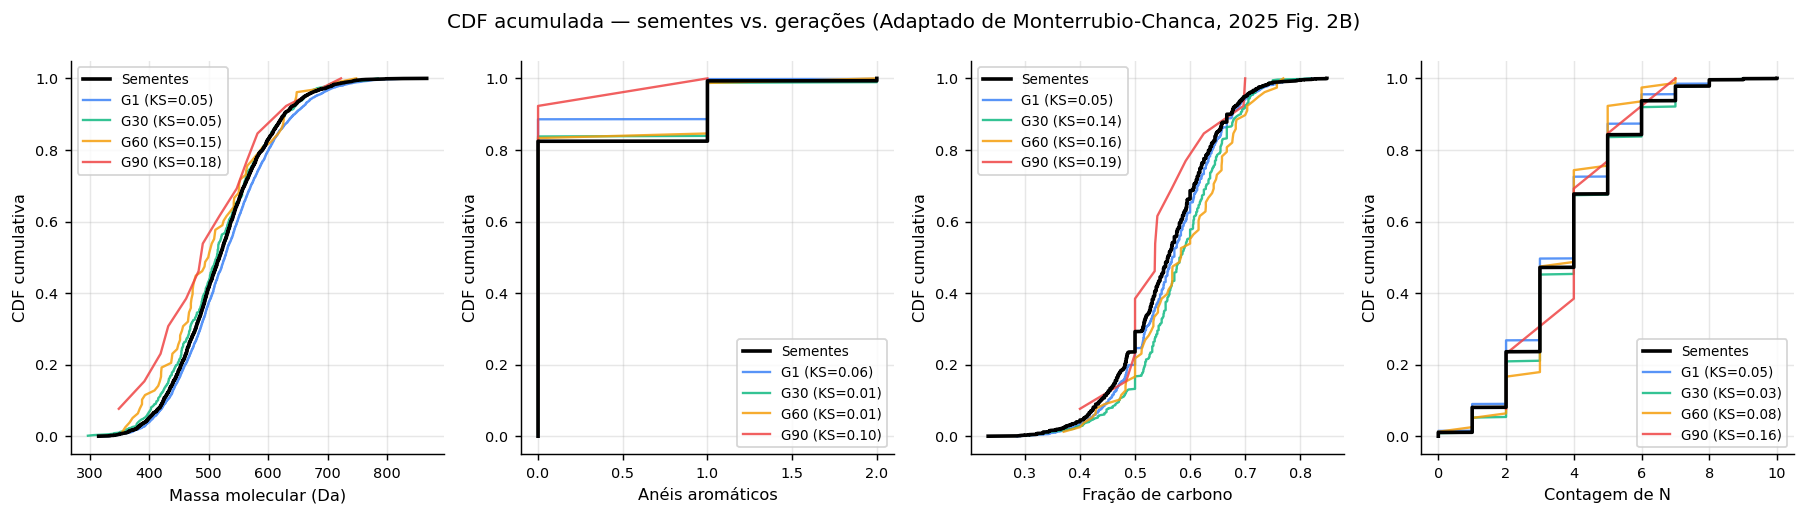

Figura salva: data/fig_cdf_geraciones.png


In [10]:
COLORS_GEN = {1: '#3b82f6', 30: '#10b981', 60: '#f59e0b', 90: '#ef4444'}

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
fig.suptitle('CDF acumulada — sementes vs. gerações (Adaptado de Monterrubio-Chanca, 2025 Fig. 2B)',
             fontsize=11)

for ax, col in zip(axes, COLS_CDF):
    # Sementes (referência)
    vals_ref = np.sort(df_seed[col].dropna().values)
    cdf_ref  = np.arange(1, len(vals_ref)+1) / len(vals_ref)
    ax.plot(vals_ref, cdf_ref, color='black', lw=2, label='Sementes', zorder=5)

    for g, df_g in sorted(dfs_gen.items()):
        vals = np.sort(df_g[col].dropna().values)
        cdf  = np.arange(1, len(vals)+1) / len(vals)
        ks, _ = ks_2samp(vals_ref, vals)
        color = COLORS_GEN.get(g, '#888888')
        ax.plot(vals, cdf, color=color, lw=1.3, alpha=0.85,
                label=f'G{g} (KS={ks:.2f})')

    ax.set_xlabel(COL_LABELS[col], fontsize=9)
    ax.set_ylabel('CDF cumulativa', fontsize=9)
    ax.legend(fontsize=7.5)
    ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig('data/fig_cdf_geraciones.png', bbox_inches='tight', dpi=150)
plt.show()
print('Figura salva: data/fig_cdf_geraciones.png')

## 5  Estimativa do viés interno da base de sementes

O artigo mostra que bases como ANI-1 (KS≈0.26) e QM9 (KS≈0.49) têm viés significativo em relação ao espaço químico subestante. Aqui medimos o **viés interno** da base de sementes via bootstrap: se a base fosse representativa, amostras aleatórias dela deveriam ter KS ≈ 0 entre si. Desvios indicam heterogeneidade/clustering estrutural.

In [11]:
np.random.seed(42)
N_BOOTSTRAP = 200
SAMPLE_SIZE  = 500

ks_boot = {col: [] for col in ['mw', 'arom_rings', 'frac_c', 'n_N', 'n_S']}

for _ in range(N_BOOTSTRAP):
    idx_a = np.random.choice(len(df_seed), SAMPLE_SIZE, replace=False)
    idx_b = np.random.choice(len(df_seed), SAMPLE_SIZE, replace=False)
    for col in ks_boot:
        stat, _ = ks_2samp(df_seed.iloc[idx_a][col].dropna().values,
                            df_seed.iloc[idx_b][col].dropna().values)
        ks_boot[col].append(stat)

print('=== Viés interno da base de sementes (bootstrap n=200, amostra=500) ===')
print(f'{"Feature":20s} {"KS médio":>10s} {"KS p95":>10s}')
print('-'*44)
for col, vals in ks_boot.items():
    print(f'{col:20s} {np.mean(vals):10.4f} {np.percentile(vals, 95):10.4f}')

print()
print('Referências (Monterrubio-Chanca, 2025 Tabela 3):')
print('  ANI-1  KS ≈ 0.26 (espaço químico 5.75×10⁴ moléculas)')
print('  QM9    KS ≈ 0.49 (espaço químico 5.9×10⁷ moléculas)')
print('  GDB-13 KS ≈ 0.44 (espaço químico 1.1×10¹⁵ moléculas)')

=== Viés interno da base de sementes (bootstrap n=200, amostra=500) ===
Feature                KS médio     KS p95
--------------------------------------------
mw                       0.0493     0.0760
arom_rings               0.0174     0.0400
frac_c                   0.0459     0.0720
n_N                      0.0334     0.0583
n_S                      0.0318     0.0540

Referências (Monterrubio-Chanca, 2025 Tabela 3):
  ANI-1  KS ≈ 0.26 (espaço químico 5.75×10⁴ moléculas)
  QM9    KS ≈ 0.49 (espaço químico 5.9×10⁷ moléculas)
  GDB-13 KS ≈ 0.44 (espaço químico 1.1×10¹⁵ moléculas)


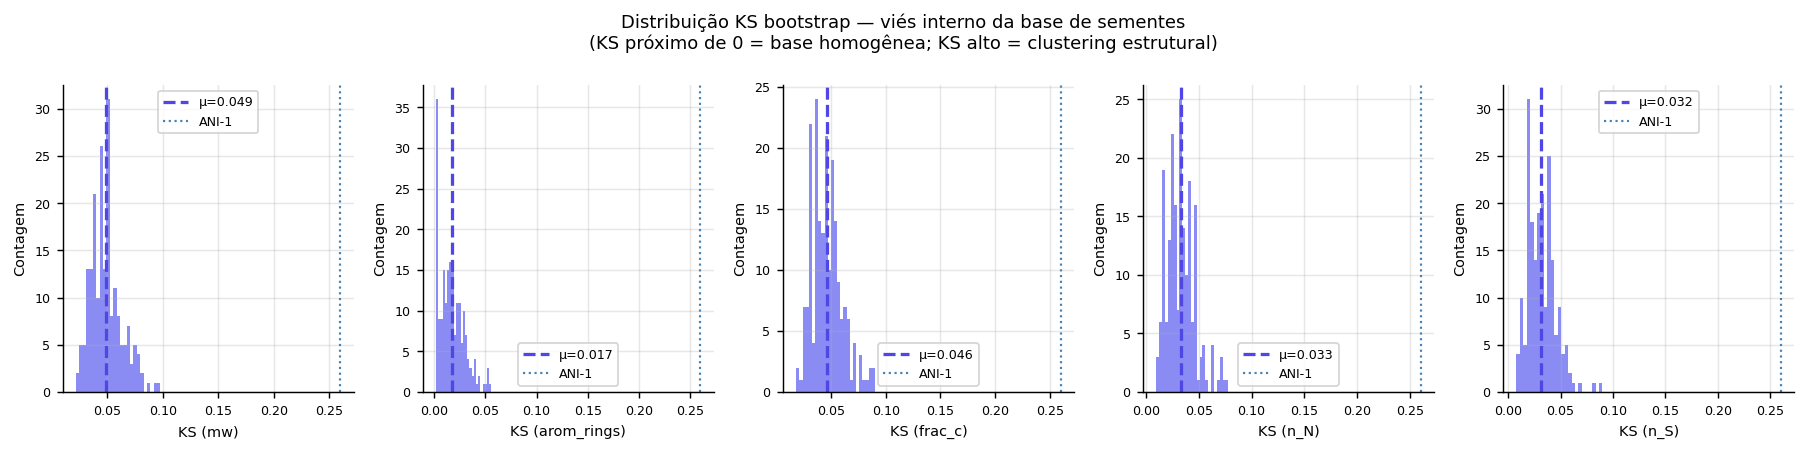

Figura salva: data/fig_ks_bootstrap.png


In [12]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.5))
fig.suptitle('Distribuição KS bootstrap — viés interno da base de sementes\n'
             '(KS próximo de 0 = base homogênea; KS alto = clustering estrutural)',
             fontsize=10)

ref_lines = {'mw': 0.26, 'arom_rings': 0.26, 'frac_c': 0.26, 'n_N': 0.26, 'n_S': 0.26}

for ax, (col, vals) in zip(axes, ks_boot.items()):
    ax.hist(vals, bins=25, color='#6366f1', alpha=0.75, edgecolor='none')
    ax.axvline(np.mean(vals), color='#4f46e5', lw=1.8, ls='--',
               label=f'μ={np.mean(vals):.3f}')
    ax.axvline(0.26, color='steelblue', lw=1.2, ls=':', label='ANI-1')
    ax.set_xlabel(f'KS ({col})', fontsize=8)
    ax.set_ylabel('Contagem', fontsize=8)
    ax.legend(fontsize=7)
    ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig('data/fig_ks_bootstrap.png', bbox_inches='tight', dpi=150)
plt.show()
print('Figura salva: data/fig_ks_bootstrap.png')

## 6  Sumário numérico — comparação G1 vs. G117 vs. Sementes

In [13]:
SHOW_COLS = ['mw', 'hac', 'n_rings', 'arom_rings', 'frac_c', 'n_N', 'n_O', 'n_S', 'heavy_hetero']
LABELS = {
    'mw': 'MW (Da)', 'hac': 'Átomos pesados', 'n_rings': 'Anéis',
    'arom_rings': 'Anéis arom.', 'frac_c': 'Fração C',
    'n_N': 'N', 'n_O': 'O', 'n_S': 'S', 'heavy_hetero': 'Heteroátomos'
}

G_FINAL = max(dfs_gen.keys()) if dfs_gen else None

summary = {}
for name, df_x in [('Sementes', df_seed),
                   ('G1',       dfs_gen.get(1, pd.DataFrame())),
                   ('G30',      dfs_gen.get(30, pd.DataFrame())),
                   (f'G{G_FINAL}', dfs_gen.get(G_FINAL, pd.DataFrame()) if G_FINAL else pd.DataFrame())]:
    if df_x.empty:
        continue
    row = {}
    for col in SHOW_COLS:
        if col in df_x.columns:
            row[LABELS[col]] = f'{df_x[col].median():.2f} ± {df_x[col].std():.2f}'
    summary[name] = row

pd.DataFrame(summary).T

,MW (Da),Átomos pesados,Anéis,Anéis arom.,Fração C,N,O,S,Heteroátomos
Sementes,518.10 ± 80.26,32.00 ± 5.33,2.00 ± 0.00,0.00 ± 0.40,0.56 ± 0.09,4.00 ± 1.71,6.00 ± 2.93,2.00 ± 1.25,14.00 ± 3.52
G1,527.08 ± 83.21,32.00 ± 5.43,2.00 ± 0.00,0.00 ± 0.33,0.57 ± 0.09,4.00 ± 1.65,7.00 ± 2.95,2.00 ± 1.23,14.00 ± 3.50
G30,513.27 ± 83.59,33.00 ± 5.53,2.00 ± 0.00,0.00 ± 0.41,0.58 ± 0.08,4.00 ± 1.67,7.00 ± 2.99,1.00 ± 1.04,14.00 ± 3.70
G90,490.14 ± 102.65,32.00 ± 6.75,2.00 ± 0.00,0.00 ± 0.28,0.54 ± 0.08,4.00 ± 1.53,8.00 ± 2.58,1.00 ± 0.87,16.00 ± 3.76


In [14]:
# KS final: geração mais avançada vs. Sementes
if G_FINAL and G_FINAL in dfs_gen:
    ks_final = ks_vs_ref(df_seed, dfs_gen[G_FINAL], cols=SHOW_COLS)
    print(f'=== KS (G{G_FINAL} vs. Sementes) ===')
    for col, val in sorted(ks_final.items(), key=lambda x: -x[1]):
        bar = '█' * int(val * 30)
        print(f'  {LABELS.get(col, col):20s}  {val:.4f}  {bar}')

=== KS (G90 vs. Sementes) ===
  O                     0.3340  ██████████
  S                     0.3153  █████████
  Fração C              0.1914  █████
  Heteroátomos          0.1867  █████
  MW (Da)               0.1845  █████
  N                     0.1641  ████
  Átomos pesados        0.1207  ███
  Anéis arom.           0.0987  ██
  Anéis                 0.0000  


## 7  Discussão e limitações

### O que esta análise mostra

1. **Viés da base de sementes**: O bootstrap KS mede a homogeneidade interna da base. Se os KS médios são comparáveis aos de ANI-1 (≈0.26) ou superiores, a base já é heterogênea — o AG parte de um espaço com viés estrutural.

2. **Deriva generacional**: O KS entre cada geração e as sementes quantifica quanto o AG explora além da base inicial. Um KS crescente indica exploração; um KS estável ou decrescente indica convergência para a região de sementes.

3. **Anéis aromáticos**: A mediana de anéis aromáticos por geração revela se o AG seleciona a favor ou contra aromáticos — relacionado diretamente à propriedade UV-Vis alvo.

### O que faltaria para uma análise RRS completa (Monterrubio-Chanca, 2025)

Para obter o KS em relação ao **espaço químico verdadeiro** (não à base de sementes), seria necessário:

```bash
pip install nablachem
```

E então gerar uma amostra uniforme do espaço anel-ponte-anel:

```python
from nablachem.space import ChemicalSpace
# Definir espaço: C, H, N, O, S; 10–30 átomos pesados
space = ChemicalSpace(elements={'C': (1,2,3,4), 'H': (1,), 'N': (3,), 'O': (2,), 'S': (2,4,6)},
                      natoms_range=(10, 30))
sample = space.sample(n=5000)  # amostra uniforme sem enumeração completa
```

Com isso, o KS seria em relação ao espaço químico subestante — análogo às Tabelas 3 de Monterrubio-Chanca — e poderia ser citado diretamente na dissertação como métrica de representatividade.

### Estimativa de tamanho do espaço anel-ponte-anel

O artigo estima o número de moléculas distintas em um espaço a partir do comprimento médio de caminho de grafos moleculares (eq. 4–10). Para o espaço anel-ponte-anel:
- Anéis de 5–6 membros com C/N: ~20 variantes de anel
- Pontes de 1–6 átomos com grupos doadores/aceptores: ~100+ variantes
- Com auxocromos: multiplicidade > 10³ por classe de anel

Estimativa grosseira (produto combinatório): **|espaço| ~ 10⁸–10¹²** moléculas distintas, colocando as 170k geradas em 0.001%–0.0000001% do espaço — evidência de que há vasto espaço inexplorado e que o AG apenas arranha a superfície.

### Recomendação para dissertação

> Cite Monterrubio-Chanca & von Rudorff (2025) para justificar a análise KS da base de sementes. A frase: *"A representatividade da base de sementes em relação ao espaço químico anel-ponte-anel foi estimada pela estatística Kolmogorov–Smirnov sobre distribuições estequiométricas, seguindo Monterrubio-Chanca & von Rudorff (2025). O KS [valor] indica [interpretação], compatível com o viés observado em bases como ANI-1 (KS≈0.26) e QM9 (KS≈0.49)."*

In [15]:
# Salvar tabela KS por geração para uso em LaTeX/dissertação
df_ks.to_csv('data/tabela_ks_geracional.csv', index=False)
print('Tabela KS salva: data/tabela_ks_geracional.csv')
print()
print('=== Estatísticas finais do KS médio ===')
g1_ks = df_ks.loc[df_ks['geracao'] == 1, 'ks_medio']
if not g1_ks.empty:
    print(f'  G1    KS médio: {g1_ks.values[0]:.4f}')
g_last = df_ks['geracao'].max()
gf_ks = df_ks.loc[df_ks['geracao'] == g_last, 'ks_medio']
if not gf_ks.empty:
    print(f'  G{g_last}  KS médio: {gf_ks.values[0]:.4f}')
print(f'  Máximo KS médio: {df_ks["ks_medio"].max():.4f} (G{df_ks.loc[df_ks["ks_medio"].idxmax(), "geracao"]})')
print(f'  Mínimo KS médio: {df_ks["ks_medio"].min():.4f} (G{df_ks.loc[df_ks["ks_medio"].idxmin(), "geracao"]})')

Tabela KS salva: data/tabela_ks_geracional.csv

=== Estatísticas finais do KS médio ===
  G1    KS médio: 0.0349
  G116  KS médio: 0.4897
  Máximo KS médio: 0.5804 (G113)
  Mínimo KS médio: 0.0349 (G1)
